# Radar Model 19 — More independent tracks, fairer evaluation, cleaner confusion matrix

**Workflow:** simulate truth → simulate radar measurements → train the existing CNN–BiGRU–attention model → evaluate on (1) unseen tracks from a familiar sensor regime and (2) a harder shifted stress-test regime → replay the unlabelled CSV packet by packet → save predictions and track summaries.

**What changed from Model 18**
- More *independent trajectories* and parameter combinations, not merely more nearly identical windows.
- Two separate test sets: an unseen-track test under familiar conditions, and a deliberately harder stress test. Their scores must not be conflated.
- Early stopping restores the best validation-loss weights; the epoch limit is higher only to give training room, not to force extra epochs.
- A clearer confusion matrix: row-normalized recall percentages with `correct / support` counts in each cell, displayed for both test regimes with consistent axes.
- The live feed is intentionally preserved: one timestamp at a time, append-only output, and no plot redraws during replay.

**Important:** the nine labels are simulator labels used only for synthetic training/evaluation. The real CSV remains unlabelled and contributes no ground-truth target labels. All ranges are illustrative simulator assumptions, not validated platform specifications. The real ICD axis convention still needs confirmation.

In [1]:
%pip -q install tensorflow numpy pandas matplotlib scikit-learn joblib

In [2]:
import os, json, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay
from tensorflow.keras.layers import (Input, Conv1D, Dense, Dropout, BatchNormalization,
    LayerNormalization, MultiHeadAttention, Bidirectional, GRU, concatenate,
    GlobalAveragePooling1D, GlobalMaxPooling1D)
from tensorflow.keras.models import Model

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); random.seed(SEED); tf.random.set_seed(SEED)

CLASSES = [
    "CIVILIAN_AIRCRAFT", "FIGHTER_AIRCRAFT", "HELICOPTER", "DRONE",
    "SURFACE_MISSILE", "AERIAL_MISSILE", "SKIFF", "BOAT", "SHIP"
]
SAMPLE_SECONDS = 10.0
SEQUENCE_LENGTH = 30
TRACKS_PER_CLASS = 24  # per class in EACH training scenario family; independent tracks matter more than epochs
TRAIN_WINDOW_STRIDE = 3
POST_BREAKOUT_CONTEXT = 8
BATCH_SIZE = 128
MAX_EPOCHS = 30  # early stopping prevents wasting epochs after validation stops improving
ARTIFACT_DIR = Path("trained_model_v19")
ARTIFACT_DIR.mkdir(exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))
# Coordinate mapping is never guessed automatically. Set True only after the ICD confirms
# that reported velocity/acceleration X and Y components are swapped relative to positions.
CONFIRM_VELOCITY_ACCEL_XY_SWAP = False

# Packet replay: append-only text, with plots only after the complete replay.
PLAYBACK_DELAY = 0.04        # seconds; set to 0.0 for fast replay
PRINT_EVERY_N_PACKETS = 1    # 1 = every timestamp, like Model 11

print("Target classes:", len(CLASSES))

TensorFlow: 2.21.0
GPU available: False
Target classes: 9


## 1. Shared Model-11-style feature extractor

We retain the 21 kinematic features that are already in your project. The simulator and the unlabelled ICD CSV use this same extractor. Uncertainty/covariance fields remain diagnostics rather than model inputs because their current ICD meaning and distribution have not been verified.

The extractor never reads target labels, metadata, or synthetic truth fields. It computes rolling/cumulative features within each track only.

In [3]:
FEATURE_COLS = [
    "pos_z", "vel_mag", "vel_xy_mag", "range_mag", "accel_mag", "jerk_mag",
    "jerk_to_accel_ratio", "curvature_3d", "specific_energy", "energy_rate",
    "z_ratio", "vertical_accel_ratio", "accel_mag_roll_mean", "accel_mag_roll_std",
    "jerk_mag_roll_mean", "jerk_mag_roll_std", "energy_rate_roll_mean",
    "energy_rate_roll_std", "cum_max_accel", "cum_max_jerk", "cum_max_energy_rate"
]
UNCERTAINTY_COLS = [
    "std_dev_x", "std_dev_y", "std_dev_z", "std_dev_vx", "std_dev_vy", "std_dev_vz",
    "std_dev_ax", "std_dev_ay", "std_dev_az", "cov_x_vx", "cov_y_vy", "cov_z_vz"
]
METADATA_NOT_FEATURES = {
    "track_no", "ntp_sec", "track_class", "track_type", "track_category_val",
    "hostility", "is_simulated", "source", "destination", "packet_size", "packet_type",
    "packet_category", "radar_id", "track_state", "manoeuvre_state", "assoc_indication"
}

def _numeric_col(df, col):
    if col not in df.columns:
        return pd.Series(np.nan, index=df.index, dtype=float)
    return pd.to_numeric(df[col], errors="coerce").astype(float)

def robust_feature_extractor(data):
    """Shared causal extractor for simulator and ICD input; never reads class metadata."""
    df = data.copy()
    if "track_no" not in df.columns:
        df["track_no"] = 1
    if "ntp_sec" not in df.columns:
        df["ntp_sec"] = np.arange(len(df), dtype=float) * SAMPLE_SECONDS
    df["ntp_sec"] = _numeric_col(df, "ntp_sec")
    df["track_no"] = df["track_no"].fillna(1)
    df = df.dropna(subset=["ntp_sec"]).sort_values(["track_no", "ntp_sec"], kind="stable").reset_index(drop=True)

    for c in ["pos_x", "pos_y", "pos_z"]:
        if c not in df.columns:
            raise ValueError(f"Required position column missing: {c}")
        df[c] = _numeric_col(df, c)

    dt = df.groupby("track_no")["ntp_sec"].diff()
    fallback_dt = SAMPLE_SECONDS  # fixed fallback; observed positive dt is still used per packet
    df["dt"] = dt.where((dt > 0) & np.isfinite(dt), fallback_dt).fillna(fallback_dt).clip(lower=0.01)

    # Preserve valid sensor-provided velocity/acceleration components. Derive only missing cells.
    for a in ["x", "y", "z"]:
        pos = _numeric_col(df, f"pos_{a}")
        derived_v = pos.groupby(df["track_no"]).diff() / df["dt"]
        provided_v = _numeric_col(df, f"vel_{a}")
        df[f"vel_{a}"] = provided_v.where(np.isfinite(provided_v), derived_v)
        df[f"vel_{a}"] = df.groupby("track_no")[f"vel_{a}"].transform(lambda s: s.ffill()).fillna(0.0)

        derived_a = df.groupby("track_no")[f"vel_{a}"].diff() / df["dt"]
        provided_a = _numeric_col(df, f"accel_{a}")
        df[f"accel_{a}"] = provided_a.where(np.isfinite(provided_a), derived_a)
        df[f"accel_{a}"] = df.groupby("track_no")[f"accel_{a}"].transform(lambda s: s.ffill()).fillna(0.0)

    v = df[["vel_x", "vel_y", "vel_z"]].to_numpy(float)
    a = df[["accel_x", "accel_y", "accel_z"]].to_numpy(float)
    dt_arr = df["dt"].to_numpy(float)

    # Trust the ICD's magnitude fields when available; these are axis-rotation invariant.
    derived_speed = np.linalg.norm(v, axis=1)
    raw_speed = _numeric_col(df, "vel_mag").to_numpy()
    df["vel_mag"] = np.where(np.isfinite(raw_speed) & (raw_speed >= 0), raw_speed, derived_speed)
    df["vel_xy_mag"] = np.sqrt(df["vel_x"]**2 + df["vel_y"]**2)
    derived_range = np.sqrt(df["pos_x"]**2 + df["pos_y"]**2 + df["pos_z"]**2)
    raw_range = _numeric_col(df, "range_mag").to_numpy()
    df["range_mag"] = np.where(np.isfinite(raw_range) & (raw_range >= 0), raw_range, derived_range)
    derived_accel = np.linalg.norm(a, axis=1)
    raw_accel = _numeric_col(df, "accel_mag").to_numpy()
    df["accel_mag"] = np.where(np.isfinite(raw_accel) & (raw_accel >= 0), raw_accel, derived_accel)

    jerk_components = np.column_stack([
        df.groupby("track_no")[f"accel_{axis}"].diff().to_numpy() / dt_arr
        for axis in ["x", "y", "z"]
    ])
    jerk_components = np.nan_to_num(jerk_components, nan=0.0, posinf=0.0, neginf=0.0)
    df["jerk_mag"] = np.linalg.norm(jerk_components, axis=1)
    df["jerk_to_accel_ratio"] = df["jerk_mag"] / np.maximum(df["accel_mag"].to_numpy(), 0.1)

    cross = np.cross(v, a)
    cross_mag = np.linalg.norm(cross, axis=1)
    df["curvature_3d"] = cross_mag / (df["vel_mag"].to_numpy()**3 + 1e-3)

    # Assumes pos_z is metres and velocity is metres/second. Change this if the ICD says otherwise.
    vz = df["vel_z"].to_numpy()
    az = df["accel_z"].to_numpy()
    df["specific_energy"] = 9.81 * df["pos_z"].to_numpy() + 0.5 * df["vel_mag"].to_numpy()**2
    df["energy_rate"] = 9.81 * vz + np.sum(v * a, axis=1)
    df["z_ratio"] = vz / (df["vel_mag"].to_numpy() + 1e-6)
    df["vertical_accel_ratio"] = az / (df["accel_mag"].to_numpy() + 1e-6)

    for col in ["accel_mag", "jerk_mag", "energy_rate"]:
        grouped = df.groupby("track_no")[col]
        df[f"{col}_roll_mean"] = grouped.transform(lambda s: s.rolling(3, min_periods=1).mean())
        df[f"{col}_roll_std"] = grouped.transform(lambda s: s.rolling(3, min_periods=2).std()).fillna(0.0)
        df[f"cum_max_{col.replace('_mag', '')}"] = grouped.cummax() if col != "energy_rate" else grouped.transform(lambda s: s.abs().cummax())

    # Normalize names to the exact 21-feature contract. Cumulative energy uses absolute magnitude.
    df["cum_max_accel"] = df.groupby("track_no")["accel_mag"].cummax()
    df["cum_max_jerk"] = df.groupby("track_no")["jerk_mag"].cummax()
    df["cum_max_energy_rate"] = df.groupby("track_no")["energy_rate"].transform(lambda s: s.abs().cummax())
    df["jerk_to_accel_ratio"] = np.log1p(np.clip(df["jerk_to_accel_ratio"], 0, 1e4))
    df["curvature_3d"] = np.log1p(np.clip(df["curvature_3d"], 0, 1e4))

    df[FEATURE_COLS] = df[FEATURE_COLS].replace([np.inf, -np.inf], np.nan)
    return df


def coordinate_frame_audit(raw):
    """Diagnostic only: compare velocity components with derivatives of position; never auto-remap."""
    if not all(c in raw.columns for c in ["pos_x", "pos_y", "pos_z", "vel_x", "vel_y", "vel_z", "ntp_sec"]):
        print("Coordinate audit skipped: position/velocity/time fields are incomplete.")
        return pd.DataFrame()
    q = raw.copy().sort_values(["track_no", "ntp_sec"] if "track_no" in raw.columns else ["ntp_sec"])
    if "track_no" in q.columns:
        dt = q.groupby("track_no")["ntp_sec"].diff().replace(0, np.nan)
    else:
        dt = q["ntp_sec"].diff().replace(0, np.nan)
    rows = []
    for vaxis in ["x", "y", "z"]:
        v = pd.to_numeric(q[f"vel_{vaxis}"], errors="coerce")
        corrs = {}
        for paxis in ["x", "y", "z"]:
            pos_series = pd.to_numeric(q[f"pos_{paxis}"], errors="coerce")
            derived = (pos_series.groupby(q["track_no"]).diff() if "track_no" in q.columns else pos_series.diff()) / dt
            corrs[paxis] = v.corr(derived)
        rows.append({"reported_velocity_axis": vaxis, **{f"corr_with_dpos_{k}": val for k, val in corrs.items()}})
    out = pd.DataFrame(rows)
    print("Position/velocity axis audit (diagnostic only; no automatic axis swapping):")
    display(out.round(3))
    for vaxis, paxes in [("x", ["x", "y"]), ("y", ["y", "x"])]:
        row = out[out["reported_velocity_axis"] == vaxis].iloc[0]
        same, other = row[f"corr_with_dpos_{paxes[0]}"], row[f"corr_with_dpos_{paxes[1]}"]
        if pd.notna(other) and (pd.isna(same) or other > same + 0.25):
            print(f"⚠️ vel_{vaxis} aligns more with d(pos_{paxes[1]}) than d(pos_{paxes[0]}). Verify the ICD axis convention before using signed axis features.")
    return out

print("Model-11-style kinematic features:", len(FEATURE_COLS))
print("Uncertainty/covariance inputs used by classifier: 0 (diagnostics only)")

Model-11-style kinematic features: 21
Uncertainty/covariance inputs used by classifier: 0 (diagnostics only)


## 2. Generate more independent tracks and realistic measurement variation

Model 18's stress test exposed a large generalization gap. This version increases the number of independent simulated tracks and keeps scenario variation explicit. More epochs alone are not the solution: early stopping will restore the best validation weights.

We will report two test results separately: (1) unseen tracks from a familiar sensor regime, which checks ordinary generalization; and (2) unseen stress conditions, which checks robustness to distribution shift. The stress result is expected to be harder and must never be pooled with the first result.

In [4]:
# Synthetic classes have overlapping envelopes by design. Ranges are illustrative priors,
# not authoritative performance envelopes for real platforms.
PROFILES = {
    "CIVILIAN_AIRCRAFT": dict(speed=(180, 310), altitude=(4500, 14000), vz=(-5, 5), turn=(0.0004, 0.006), sea=False),
    "FIGHTER_AIRCRAFT":   dict(speed=(220, 900), altitude=(200, 19000), vz=(-22, 22), turn=(0.001, 0.028), sea=False),
    "HELICOPTER":         dict(speed=(15, 115), altitude=(10, 4500), vz=(-7, 7), turn=(0.008, 0.055), sea=False),
    "DRONE":              dict(speed=(5, 230), altitude=(10, 13000), vz=(-12, 12), turn=(0.004, 0.050), sea=False),
    "SURFACE_MISSILE":    dict(speed=(260, 1250), altitude=(5, 100), vz=(-16, 16), turn=(0.001, 0.025), sea=False),
    "AERIAL_MISSILE":     dict(speed=(350, 1600), altitude=(500, 26000), vz=(-40, 40), turn=(0.002, 0.035), sea=False),
    "SKIFF":              dict(speed=(1, 22), altitude=(1, 4), vz=(0, 0), turn=(0.001, 0.025), sea=True),
    "BOAT":               dict(speed=(2, 28), altitude=(2, 10), vz=(0, 0), turn=(0.0005, 0.016), sea=True),
    "SHIP":               dict(speed=(1, 18), altitude=(5, 28), vz=(0, 0), turn=(0.0002, 0.008), sea=True),
}

# The three training families vary sensor quality and manoeuvres. Validation and test are
# whole held-out scenario families, not random windows from the training distribution.
SCENARIO_SETTINGS = {
    "nominal_train":       dict(sensor_mult=0.85, dropout=0.00, outlier=0.000, maneuver_p=0.20, sea_state="calm"),
    "moderate_noise_train":dict(sensor_mult=1.25, dropout=0.015, outlier=0.004, maneuver_p=0.35, sea_state="moderate"),
    "maneuver_mix_train":  dict(sensor_mult=1.05, dropout=0.020, outlier=0.006, maneuver_p=0.65, sea_state="moderate"),
    "validation_shift":    dict(sensor_mult=1.45, dropout=0.035, outlier=0.010, maneuver_p=0.50, sea_state="rough"),
    # Independent tracks from a familiar regime: no trajectory is reused from training.
    "heldout_iid_test":    dict(sensor_mult=1.15, dropout=0.018, outlier=0.004, maneuver_p=0.38, sea_state="moderate"),
    # Deliberately harder distribution shift; interpret separately from IID generalization.
    "stress_unseen_test":  dict(sensor_mult=1.85, dropout=0.060, outlier=0.018, maneuver_p=0.68, sea_state="rough"),
}
TRAIN_FAMILIES = ["nominal_train", "moderate_noise_train", "maneuver_mix_train"]
VALIDATION_FAMILY = "validation_shift"
IID_TEST_FAMILY = "heldout_iid_test"
STRESS_TEST_FAMILY = "stress_unseen_test"
TEST_FAMILY = STRESS_TEST_FAMILY  # retained for the existing static vessel diagnostic
TRACKS_PER_CLASS_TRAIN_FAMILY = TRACKS_PER_CLASS
TRACKS_PER_CLASS_VALIDATION = 12
TRACKS_PER_CLASS_IID_TEST = 12
TRACKS_PER_CLASS_TEST = 15

# A disguise changes early motion, not the physical identity label. Keep only post-breakout
# contexts as supervised identity windows; early ambiguous prefixes are intentionally excluded.
MIMIC_PROFILES = {
    "FIGHTER_AIRCRAFT": dict(speed=(220, 300), altitude=(6500, 14000), turn=(0.0003, 0.005)),
    "DRONE": dict(speed=(20, 95), altitude=(30, 2800), turn=(0.004, 0.025)),
    "AERIAL_MISSILE": dict(speed=(300, 800), altitude=(1000, 18000), turn=(0.001, 0.012)),
}

SEA_RESPONSE = {
    # Amplitude ranges for the low-frequency motion seen in a track report. Faster wave
    # components are attenuated by typical tracking/filtering and may be under-sampled.
    "calm": (0.12, 0.45),
    "moderate": (0.35, 1.10),
    "rough": (0.80, 2.40),
}
VESSEL_RESPONSE_SCALE = {"SKIFF": 1.0, "BOAT": 1.35, "SHIP": 1.65}


def _smoothstep01(x):
    x = float(np.clip(x, 0.0, 1.0))
    return x*x*(3.0 - 2.0*x)


def generate_complex_trajectory(target_class, track_id, rng, scenario_family, duration=None):
    """Generate a physical trajectory, then an imperfect radar measurement stream.

    `_true_*` columns are simulator diagnostics only. Model features are computed exclusively
    from reported measurement columns. `track_class`/metadata are never model inputs.
    """
    spec = PROFILES[target_class]
    settings = SCENARIO_SETTINGS[scenario_family]
    n = int(duration if duration is not None else rng.integers(55, 87))
    dt = SAMPLE_SECONDS
    is_sea = bool(spec["sea"])
    sea_state = settings["sea_state"] if is_sea else "not_applicable"

    # Physical height: an aircraft's altitude or a vessel's radar-reflection reference height.
    if target_class == "SURFACE_MISSILE":
        base_z = float(rng.uniform(5, 100) if rng.random() < 0.70 else rng.uniform(500, 7000))
    elif is_sea:
        base_z = float(rng.uniform(*spec["altitude"]))
    else:
        base_z = float(rng.uniform(*spec["altitude"]))

    base_speed = float(rng.uniform(*spec["speed"]))
    heading = float(rng.uniform(-np.pi, np.pi))
    radius0 = float(rng.uniform(25_000, 140_000))
    bearing0 = float(rng.uniform(-np.pi, np.pi))
    center_pos = np.array([radius0*np.cos(bearing0), radius0*np.sin(bearing0), 0.0 if is_sea else base_z], dtype=float)

    # Current/wind drift is part of true ground motion, not measurement noise.
    if is_sea:
        current_speed = float(rng.uniform(0.05, 1.2))
        current_heading = float(rng.uniform(-np.pi, np.pi))
    else:
        current_speed = float(rng.uniform(0.0, 2.0))
        current_heading = float(rng.uniform(-np.pi, np.pi))
    current_xy = np.array([current_speed*np.cos(current_heading), current_speed*np.sin(current_heading)])

    is_disguised = bool(target_class in MIMIC_PROFILES and rng.random() < 0.25)
    breakout_step = int(rng.integers(max(14, n//3), max(15, 2*n//3)) if is_disguised else -1)
    mimic = MIMIC_PROFILES.get(target_class, None) if is_disguised else None
    mimic_speed = float(rng.uniform(*mimic["speed"])) if mimic else base_speed
    if mimic and not is_sea:
        base_z = float(rng.uniform(*mimic["altitude"]))
        center_pos[2] = base_z
    mimic_turn = float(rng.uniform(*mimic["turn"])) if mimic else float(rng.uniform(*spec["turn"]))
    turn_rate = float(rng.uniform(*spec["turn"]))

    # Randomly choose a smooth mid-track manoeuvre. The scenario family controls how often it occurs.
    has_manoeuvre = bool(rng.random() < settings["maneuver_p"])
    event_center = int(rng.integers(16, max(17, n-12))) if has_manoeuvre else -999
    event_width = float(rng.uniform(4, 10)) if has_manoeuvre else 1.0
    event_turn = float(rng.choice([-1, 1]) * rng.uniform(*spec["turn"]) * rng.uniform(0.5, 1.4)) if has_manoeuvre else 0.0
    event_speed_delta = float(rng.uniform(-0.18, 0.22) * base_speed) if has_manoeuvre else 0.0
    event_climb = float(rng.uniform(-0.25, 0.25) * max(abs(spec["vz"][1]), 1.0)) if (has_manoeuvre and not is_sea) else 0.0

    # Low-frequency wave response: heave plus small roll/pitch-driven apparent reflection shifts.
    if is_sea:
        amp_low, amp_high = SEA_RESPONSE[sea_state]
        vessel_scale = VESSEL_RESPONSE_SCALE[target_class]
        heave_amps = rng.uniform(amp_low, amp_high, size=2) * vessel_scale
        periods = rng.uniform(22.0, 58.0, size=2)  # filtered track-level swell, not raw wave period
        phases = rng.uniform(-np.pi, np.pi, size=2)
        sway_amps = rng.uniform(0.15, 0.55, size=2) * vessel_scale * (1.0 if sea_state == "calm" else 1.8)
        sway_periods = rng.uniform(24.0, 64.0, size=2)
        sway_phases = rng.uniform(-np.pi, np.pi, size=2)
    else:
        heave_amps = np.zeros(2); periods = np.array([30.0, 45.0]); phases = np.zeros(2)
        sway_amps = np.zeros(2); sway_periods = np.array([30.0, 45.0]); sway_phases = np.zeros(2)

    # Sensor noise is range/scenario dependent and class-independent. AR(1) bias makes errors
    # temporally correlated; occasional outliers and missed detections model imperfect tracking.
    pos_bias = np.zeros(3); vel_bias = np.zeros(3); acc_bias = np.zeros(3)
    previous_true_v = None
    previous_true_a = None
    rows = []
    jitter = 0.0
    for step in range(n):
        t = step * dt
        if mimic and step < breakout_step:
            blend = 0.0
        elif mimic:
            blend = _smoothstep01((step - breakout_step + 1) / 6.0)
        else:
            blend = 1.0
        desired_speed = mimic_speed*(1-blend) + base_speed*blend
        event_strength = np.exp(-0.5*((step-event_center)/event_width)**2) if has_manoeuvre else 0.0
        target_turn_limit = mimic_turn*(1-blend) + float(np.mean(spec["turn"]))*blend if mimic else float(np.mean(spec["turn"]))
        turn_rate += rng.normal(0, max(target_turn_limit*0.10, 1e-5))
        turn_rate += event_turn * event_strength * dt * 0.025
        turn_rate = float(np.clip(turn_rate, -max(target_turn_limit, 1e-4)*1.8, max(target_turn_limit, 1e-4)*1.8))
        heading += turn_rate * dt
        speed_noise = max(0.015*base_speed, 0.15) * settings["sensor_mult"]
        speed = float(np.clip(desired_speed + rng.normal(0, speed_noise) + event_speed_delta*event_strength,
                              max(0.1, spec["speed"][0]*0.55), spec["speed"][1]*1.10))

        if is_sea:
            true_vz_center = 0.0
            center_velocity = np.array([speed*np.cos(heading)+current_xy[0], speed*np.sin(heading)+current_xy[1], 0.0])
        else:
            vz_limit = max(abs(spec["vz"][1]), 1.0)
            climb = event_climb * event_strength
            true_vz_center = float(np.clip(rng.normal(0, max(vz_limit*0.12, 0.15)) + climb, -vz_limit, vz_limit))
            horiz = np.sqrt(max(speed*speed - true_vz_center*true_vz_center, 0.0))
            center_velocity = np.array([horiz*np.cos(heading)+current_xy[0], horiz*np.sin(heading)+current_xy[1], true_vz_center])

        if step > 0:
            center_pos = center_pos + center_velocity * dt

        if is_sea:
            omega = 2*np.pi/periods
            heave = float(np.sum(heave_amps * np.sin(omega*t + phases)))
            heave_v = float(np.sum(heave_amps * omega * np.cos(omega*t + phases)))
            heave_a = float(-np.sum(heave_amps * omega**2 * np.sin(omega*t + phases)))
            sway_omega = 2*np.pi/sway_periods
            sway_x = float(np.sum(sway_amps * np.sin(sway_omega*t + sway_phases)))
            sway_vx = float(np.sum(sway_amps * sway_omega * np.cos(sway_omega*t + sway_phases)))
            sway_ax = float(-np.sum(sway_amps * sway_omega**2 * np.sin(sway_omega*t + sway_phases)))
            sway_y = float(np.sum(0.65*sway_amps * np.sin(sway_omega*t + sway_phases + 0.9)))
            sway_vy = float(np.sum(0.65*sway_amps * sway_omega * np.cos(sway_omega*t + sway_phases + 0.9)))
            sway_ay = float(-np.sum(0.65*sway_amps * sway_omega**2 * np.sin(sway_omega*t + sway_phases + 0.9)))
            true_pos = np.array([center_pos[0] + sway_x, center_pos[1] + sway_y, base_z + heave])
            true_v = np.array([center_velocity[0] + sway_vx, center_velocity[1] + sway_vy, heave_v])
            wave_a = np.array([sway_ax, sway_ay, heave_a])
        else:
            true_pos = center_pos.copy()
            true_v = center_velocity.copy()
            wave_a = np.zeros(3)
        if previous_true_v is None:
            true_a = wave_a.copy()
        else:
            true_a = (true_v - previous_true_v) / dt
        true_speed = float(np.linalg.norm(true_v))
        true_range = float(np.linalg.norm(true_pos))

        # Noise depends on range and scenario, not on the target class.
        sigma_p = float(np.clip(8.0 + true_range*0.00016, 8.0, 65.0) * settings["sensor_mult"])
        sigma_v = float(np.clip(0.25 + true_range*0.000006, 0.25, 2.2) * settings["sensor_mult"])
        sigma_a = float(np.clip(0.08 + true_speed*0.0020, 0.10, 1.8) * settings["sensor_mult"])
        pos_sigmas = np.array([sigma_p, sigma_p*rng.uniform(0.85, 1.15), sigma_p*rng.uniform(0.80, 1.25)])
        vel_sigmas = np.array([sigma_v, sigma_v*rng.uniform(0.85, 1.20), sigma_v*rng.uniform(0.80, 1.25)])
        acc_sigmas = np.array([sigma_a, sigma_a*rng.uniform(0.80, 1.25), sigma_a*rng.uniform(0.80, 1.25)])
        pos_bias = 0.72*pos_bias + rng.normal(0, pos_sigmas*0.22, 3)
        vel_bias = 0.62*vel_bias + rng.normal(0, vel_sigmas*0.22, 3)
        acc_bias = 0.55*acc_bias + rng.normal(0, acc_sigmas*0.18, 3)
        obs_pos = true_pos + pos_bias + rng.normal(0, pos_sigmas*0.70, 3)
        obs_v = true_v + vel_bias + rng.normal(0, vel_sigmas*0.75, 3)
        obs_a = true_a + acc_bias + rng.normal(0, acc_sigmas*0.80, 3)
        is_outlier = bool(rng.random() < settings["outlier"])
        if is_outlier:
            obs_pos += rng.normal(0, pos_sigmas*6.0, 3)
            obs_v += rng.normal(0, vel_sigmas*3.5, 3)
            obs_a += rng.normal(0, acc_sigmas*3.0, 3)

        # Ensure timestamps are strictly increasing despite small timestamp jitter.
        jitter += float(rng.normal(0, 0.035))
        timestamp = 1_700_000_000.0 + t + jitter
        previous_true_v = true_v.copy()
        previous_true_a = true_a.copy()

        # A dropout removes an observation but the physical trajectory continues through the gap.
        if step not in (0, n-1) and rng.random() < settings["dropout"]:
            continue

        rows.append({
            "track_no": track_id, "ntp_sec": timestamp,
            "pos_x": obs_pos[0], "pos_y": obs_pos[1], "pos_z": obs_pos[2],
            "vel_x": obs_v[0], "vel_y": obs_v[1], "vel_z": obs_v[2],
            "vel_mag": np.linalg.norm(obs_v), "range_mag": np.linalg.norm(obs_pos),
            "accel_x": obs_a[0], "accel_y": obs_a[1], "accel_z": obs_a[2], "accel_mag": np.linalg.norm(obs_a),
            "std_dev_x": pos_sigmas[0], "std_dev_y": pos_sigmas[1], "std_dev_z": pos_sigmas[2],
            "std_dev_vx": vel_sigmas[0], "std_dev_vy": vel_sigmas[1], "std_dev_vz": vel_sigmas[2],
            "std_dev_ax": acc_sigmas[0], "std_dev_ay": acc_sigmas[1], "std_dev_az": acc_sigmas[2],
            "cov_x_vx": rng.uniform(-0.25, 0.25)*pos_sigmas[0]*vel_sigmas[0],
            "cov_y_vy": rng.uniform(-0.25, 0.25)*pos_sigmas[1]*vel_sigmas[1],
            "cov_z_vz": rng.uniform(-0.25, 0.25)*pos_sigmas[2]*vel_sigmas[2],
            # Ground truth is retained only to train/evaluate synthetic data. It is never a feature.
            "_true_pos_x": true_pos[0], "_true_pos_y": true_pos[1], "_true_pos_z": true_pos[2],
            "_true_vel_x": true_v[0], "_true_vel_y": true_v[1], "_true_vel_z": true_v[2],
            "_true_class": target_class, "_scenario_family": scenario_family,
            "_is_disguised": is_disguised, "_breakout_step": breakout_step, "_step": step,
            "_sea_state": sea_state, "_sensor_outlier": is_outlier,
        })
    return pd.DataFrame(rows)


def generate_dataset():
    rng = np.random.default_rng(SEED)
    frames = []
    track_id = 10_000
    for family, count in [(f, TRACKS_PER_CLASS_TRAIN_FAMILY) for f in TRAIN_FAMILIES] + [
        (VALIDATION_FAMILY, TRACKS_PER_CLASS_VALIDATION),
        (IID_TEST_FAMILY, TRACKS_PER_CLASS_IID_TEST),
        (STRESS_TEST_FAMILY, TRACKS_PER_CLASS_TEST),
    ]:
        for cls in CLASSES:
            for _ in range(count):
                frames.append(generate_complex_trajectory(cls, track_id, rng, family))
                track_id += 1
    out = pd.concat(frames, ignore_index=True)
    return out.sort_values(["track_no", "ntp_sec"], kind="stable").reset_index(drop=True)

print("Three-layer synthetic simulator ready.")
print("Training families:", TRAIN_FAMILIES)
print("Held-out validation family:", VALIDATION_FAMILY)
print("Held-out IID test family:", IID_TEST_FAMILY)
print("Held-out stress test family:", STRESS_TEST_FAMILY)

Three-layer synthetic simulator ready.
Training families: ['nominal_train', 'moderate_noise_train', 'maneuver_mix_train']
Held-out validation family: validation_shift
Held-out IID test family: heldout_iid_test
Held-out stress test family: stress_unseen_test


## 3. Split by scenario family — with two distinct test questions

- **Train:** three families, with many independently sampled trajectories per class.
- **Validation:** a separate family used for early stopping and learning-rate decisions.
- **IID test:** unseen tracks from a familiar measurement regime; this estimates generalization to new tracks under broadly familiar conditions.
- **Stress test:** unseen tracks with harder noise/dropout/sea-state settings; this estimates robustness to shift.

No physical track appears in more than one split. Fit the imputer and scaler on training-family rows only. Do not use stress-test results to tune the model.

In [5]:
synthetic_raw = generate_dataset()
print("Synthetic observed rows:", len(synthetic_raw), "| tracks:", synthetic_raw["track_no"].nunique())
print("Surface-vessel packets:", int(synthetic_raw["_true_class"].isin(["SKIFF", "BOAT", "SHIP"]).sum()))
print("Tracks with simulated disguise:", int(synthetic_raw.groupby("track_no")["_is_disguised"].first().sum()))
assert synthetic_raw.groupby("track_no")["_true_class"].nunique().max() == 1, "Identity must stay constant within a track."
assert synthetic_raw.groupby("track_no")["_scenario_family"].nunique().max() == 1, "A track must belong to one scenario family."

track_table = synthetic_raw.groupby("track_no", sort=False).agg(
    true_class=("_true_class", "first"), scenario_family=("_scenario_family", "first")
).reset_index()
train_ids = set(track_table.loc[track_table["scenario_family"].isin(TRAIN_FAMILIES), "track_no"])
val_ids = set(track_table.loc[track_table["scenario_family"] == VALIDATION_FAMILY, "track_no"])
iid_test_ids = set(track_table.loc[track_table["scenario_family"] == IID_TEST_FAMILY, "track_no"])
stress_test_ids = set(track_table.loc[track_table["scenario_family"] == STRESS_TEST_FAMILY, "track_no"])

split_sets = [train_ids, val_ids, iid_test_ids, stress_test_ids]
for i in range(len(split_sets)):
    for j in range(i + 1, len(split_sets)):
        assert split_sets[i].isdisjoint(split_sets[j]), "A physical track leaked between splits."
assert set(track_table.loc[track_table.track_no.isin(train_ids), "scenario_family"]) == set(TRAIN_FAMILIES)
assert set(track_table.loc[track_table.track_no.isin(val_ids), "scenario_family"]) == {VALIDATION_FAMILY}
assert set(track_table.loc[track_table.track_no.isin(iid_test_ids), "scenario_family"]) == {IID_TEST_FAMILY}
assert set(track_table.loc[track_table.track_no.isin(stress_test_ids), "scenario_family"]) == {STRESS_TEST_FAMILY}
print(f"Track split — train: {len(train_ids)}, validation: {len(val_ids)}, IID test: {len(iid_test_ids)}, stress test: {len(stress_test_ids)}")
print("Track-level split integrity passed: every track belongs to exactly one family split.")

# Same feature extractor for simulated reports and real ICD CSV.
sim_features = robust_feature_extractor(synthetic_raw)
train_rows = sim_features[sim_features["track_no"].isin(train_ids)]
imputer = SimpleImputer(strategy="median")
scaler = RobustScaler(quantile_range=(10, 90))
imputer.fit(train_rows[FEATURE_COLS])
scaler.fit(imputer.transform(train_rows[FEATURE_COLS]))
scaled_array = scaler.transform(imputer.transform(sim_features[FEATURE_COLS]))
scaled_array = np.clip(scaled_array, -8, 8)
sim_scaled = sim_features.copy()
sim_scaled.loc[:, FEATURE_COLS] = scaled_array
label_encoder = LabelEncoder().fit(CLASSES)

# Build fixed-length windows within each track. True identity is constant across its whole track.
def make_sequences(frame, allowed_track_ids, stride=TRAIN_WINDOW_STRIDE, skip_disguise_prefix=True):
    xs, ys, metas = [], [], []
    subset = frame[frame["track_no"].isin(allowed_track_ids)]
    for tid, g in subset.groupby("track_no", sort=False):
        g = g.sort_values("ntp_sec", kind="stable").reset_index(drop=True)
        x = g[FEATURE_COLS].to_numpy(dtype=np.float32)
        label = str(g["_true_class"].iloc[0])
        disguised = bool(g["_is_disguised"].iloc[0])
        breakout = int(g["_breakout_step"].iloc[0])
        valid_ends = list(range(SEQUENCE_LENGTH - 1, len(g), stride))
        if not valid_ends or valid_ends[-1] != len(g) - 1:
            valid_ends.append(len(g) - 1)
        for end in valid_ends:
            if skip_disguise_prefix and disguised and end < breakout + POST_BREAKOUT_CONTEXT:
                continue
            start = end - SEQUENCE_LENGTH + 1
            if start < 0:
                continue
            xs.append(x[start:end+1])
            ys.append(label_encoder.transform([label])[0])
            metas.append({"track_no": tid, "true_class": label, "end_index": end,
                          "ntp_sec": float(g["ntp_sec"].iloc[end]), "is_final": end == len(g)-1,
                          "is_disguised": disguised, "breakout_step": breakout,
                          "scenario_family": str(g["_scenario_family"].iloc[0])})
    return np.asarray(xs, dtype=np.float32), np.asarray(ys, dtype=np.int64), pd.DataFrame(metas)

X_train, y_train, meta_train = make_sequences(sim_scaled, train_ids)
X_val, y_val, meta_val = make_sequences(sim_scaled, val_ids)
X_iid_test, y_iid_test, meta_iid_test = make_sequences(sim_scaled, iid_test_ids)
X_stress_test, y_stress_test, meta_stress_test = make_sequences(sim_scaled, stress_test_ids)
print("Sequence shapes:", "train", X_train.shape, "val", X_val.shape,
      "IID test", X_iid_test.shape, "stress test", X_stress_test.shape)
assert not (set(meta_train.track_no) & set(meta_val.track_no))
assert not (set(meta_train.track_no) & set(meta_iid_test.track_no))
assert not (set(meta_train.track_no) & set(meta_stress_test.track_no))
assert X_train.shape[1:] == (SEQUENCE_LENGTH, len(FEATURE_COLS))
assert meta_train["scenario_family"].isin(TRAIN_FAMILIES).all()
assert set(meta_val["scenario_family"]) == {VALIDATION_FAMILY}
assert set(meta_iid_test["scenario_family"]) == {IID_TEST_FAMILY}
assert set(meta_stress_test["scenario_family"]) == {STRESS_TEST_FAMILY}
print("No physical-track leakage. IID and stress results will be reported separately.")

Synthetic observed rows: 69425 | tracks: 999
Surface-vessel packets: 22922
Tracks with simulated disguise: 97
Track split — train: 648, validation: 108, IID test: 108, stress test: 135
Track-level split integrity passed: every track belongs to exactly one family split.
Sequence shapes: train (9247, 30, 21) val (1448, 30, 21) IID test (1467, 30, 21) stress test (1808, 30, 21)
No physical-track leakage. IID and stress results will be reported separately.


## 4. Train the existing CNN–BiGRU–attention architecture

We keep the model architecture stable so that the next experiment isolates the effect of more independent tracks and better evaluation. The epoch cap is 30, but **do not aim to reach 30**: early stopping restores the best validation-loss weights. More epochs without new information would only encourage overfitting.

In [6]:
def build_radar_model(input_shape, num_classes):
    inputs = Input(shape=input_shape)
    c1 = Conv1D(32, kernel_size=3, padding="same", activation="relu")(inputs)
    c2 = Conv1D(32, kernel_size=5, padding="same", activation="relu")(inputs)
    x = BatchNormalization()(concatenate([c1, c2]))
    x = Bidirectional(GRU(64, return_sequences=True, dropout=0.20))(x)
    attn = MultiHeadAttention(num_heads=4, key_dim=32, dropout=0.10)(x, x)
    x = LayerNormalization()(x + attn)
    pooled = concatenate([GlobalAveragePooling1D()(x), GlobalMaxPooling1D()(x)])
    x = Dense(96, activation="relu")(pooled)
    x = BatchNormalization()(x)
    x = Dropout(0.35)(x)
    outputs = Dense(num_classes, activation="softmax")(x)
    model = Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

model = build_radar_model((SEQUENCE_LENGTH, len(FEATURE_COLS)), len(CLASSES))
model.summary()
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)
]
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=MAX_EPOCHS,
                    batch_size=BATCH_SIZE, callbacks=callbacks, verbose=1)

model.save(ARTIFACT_DIR / "radar_target_classifier.keras")
joblib.dump(imputer, ARTIFACT_DIR / "feature_imputer.pkl")
joblib.dump(scaler, ARTIFACT_DIR / "feature_scaler.pkl")
joblib.dump(label_encoder, ARTIFACT_DIR / "label_encoder.pkl")
joblib.dump(FEATURE_COLS, ARTIFACT_DIR / "feature_columns_list.pkl")
with open(ARTIFACT_DIR / "radar_config.json", "w") as f:
    json.dump({"sequence_length": SEQUENCE_LENGTH, "feature_cols": FEATURE_COLS,
               "target_classes": CLASSES, "feature_version": "model11_physics_21_no_torsion_truth_sensor_split_wave_motion_v19_more_tracks_two_tests"}, f, indent=2)
print("Saved model bundle to:", ARTIFACT_DIR.resolve())

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30, 21)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 30, 32)    │      2,048 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 30, 32)    │      3,392 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 30, 64)    │          0 │ conv1d[0][0],     │
│ (Concatenate)       │                   │            │ conv1d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 30, 64)    │        256 │ concatenate[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 30, 128)   │     49,920 │ batch_normalizat… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 128)   │     66,048 │ bidirectional[0]… │
│ (MultiHeadAttentio… │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 30, 128)   │          0 │ bidirectional[0]… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 30, 128)   │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ layer_normalizat… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 256)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 96)        │     24,672 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 96)        │        384 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 96)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 9)         │        873 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 147,849 (577.54 KB)

 Trainable params: 147,529 (576.29 KB)

 Non-trainable params: 320 (1.25 KB)

Epoch 1/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 26s 252ms/step - accuracy: 0.5884 - loss: 1.0392 - val_accuracy: 0.5000 - val_loss: 1.1958 - learning_rate: 0.0010
Epoch 2/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 19s 254ms/step - accuracy: 0.6921 - loss: 0.7218 - val_accuracy: 0.6174 - val_loss: 0.8132 - learning_rate: 0.0010
Epoch 3/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 17s 233ms/step - accuracy: 0.7395 - loss: 0.6010 - val_accuracy: 0.6506 - val_loss: 0.7628 - learning_rate: 0.0010
Epoch 4/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 18s 244ms/step - accuracy: 0.7716 - loss: 0.5291 - val_accuracy: 0.7058 - val_loss: 0.6919 - learning_rate: 0.0010
Epoch 5/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 20s 235ms/step - accuracy: 0.7939 - loss: 0.4817 - val_accuracy: 0.6934 - val_loss: 0.6949 - learning_rate: 0.0010
Epoch 6/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 23s 277ms/step - accuracy: 0.8318 - loss: 0.4103 - val_accuracy: 0.7251 - val_loss: 0.7088 - learning_rate: 0.0010
Epoch 7/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 18s 247ms/step - accuracy: 0.8601 - loss: 0.

## 5. Evaluate per track, with a readable confusion matrix

The primary unit is one vote per physical track, not one vote per highly overlapping window. We report both a familiar-regime unseen-track test and a harder stress test. Each confusion matrix is row-normalized (per-class recall) and each cell also displays the raw `correct / support` count. This makes class-specific errors easier to read and prevents classes with more windows from dominating the visual result.


IID unseen-track test — TRACK-level accuracy: 0.750 (81/108)
                   precision    recall  f1-score   support

CIVILIAN_AIRCRAFT       0.92      1.00      0.96        12
 FIGHTER_AIRCRAFT       0.80      0.33      0.47        12
       HELICOPTER       0.86      1.00      0.92        12
            DRONE       1.00      0.83      0.91        12
  SURFACE_MISSILE       0.62      0.83      0.71        12
   AERIAL_MISSILE       0.79      0.92      0.85        12
            SKIFF       0.54      0.58      0.56        12
             BOAT       0.53      0.75      0.62        12
             SHIP       1.00      0.50      0.67        12

         accuracy                           0.75       108
        macro avg       0.78      0.75      0.74       108
     weighted avg       0.78      0.75      0.74       108


Unseen stress test — TRACK-level accuracy: 0.681 (92/135)
                   precision    recall  f1-score   support

CIVILIAN_AIRCRAFT       1.00      0.80      0.89 

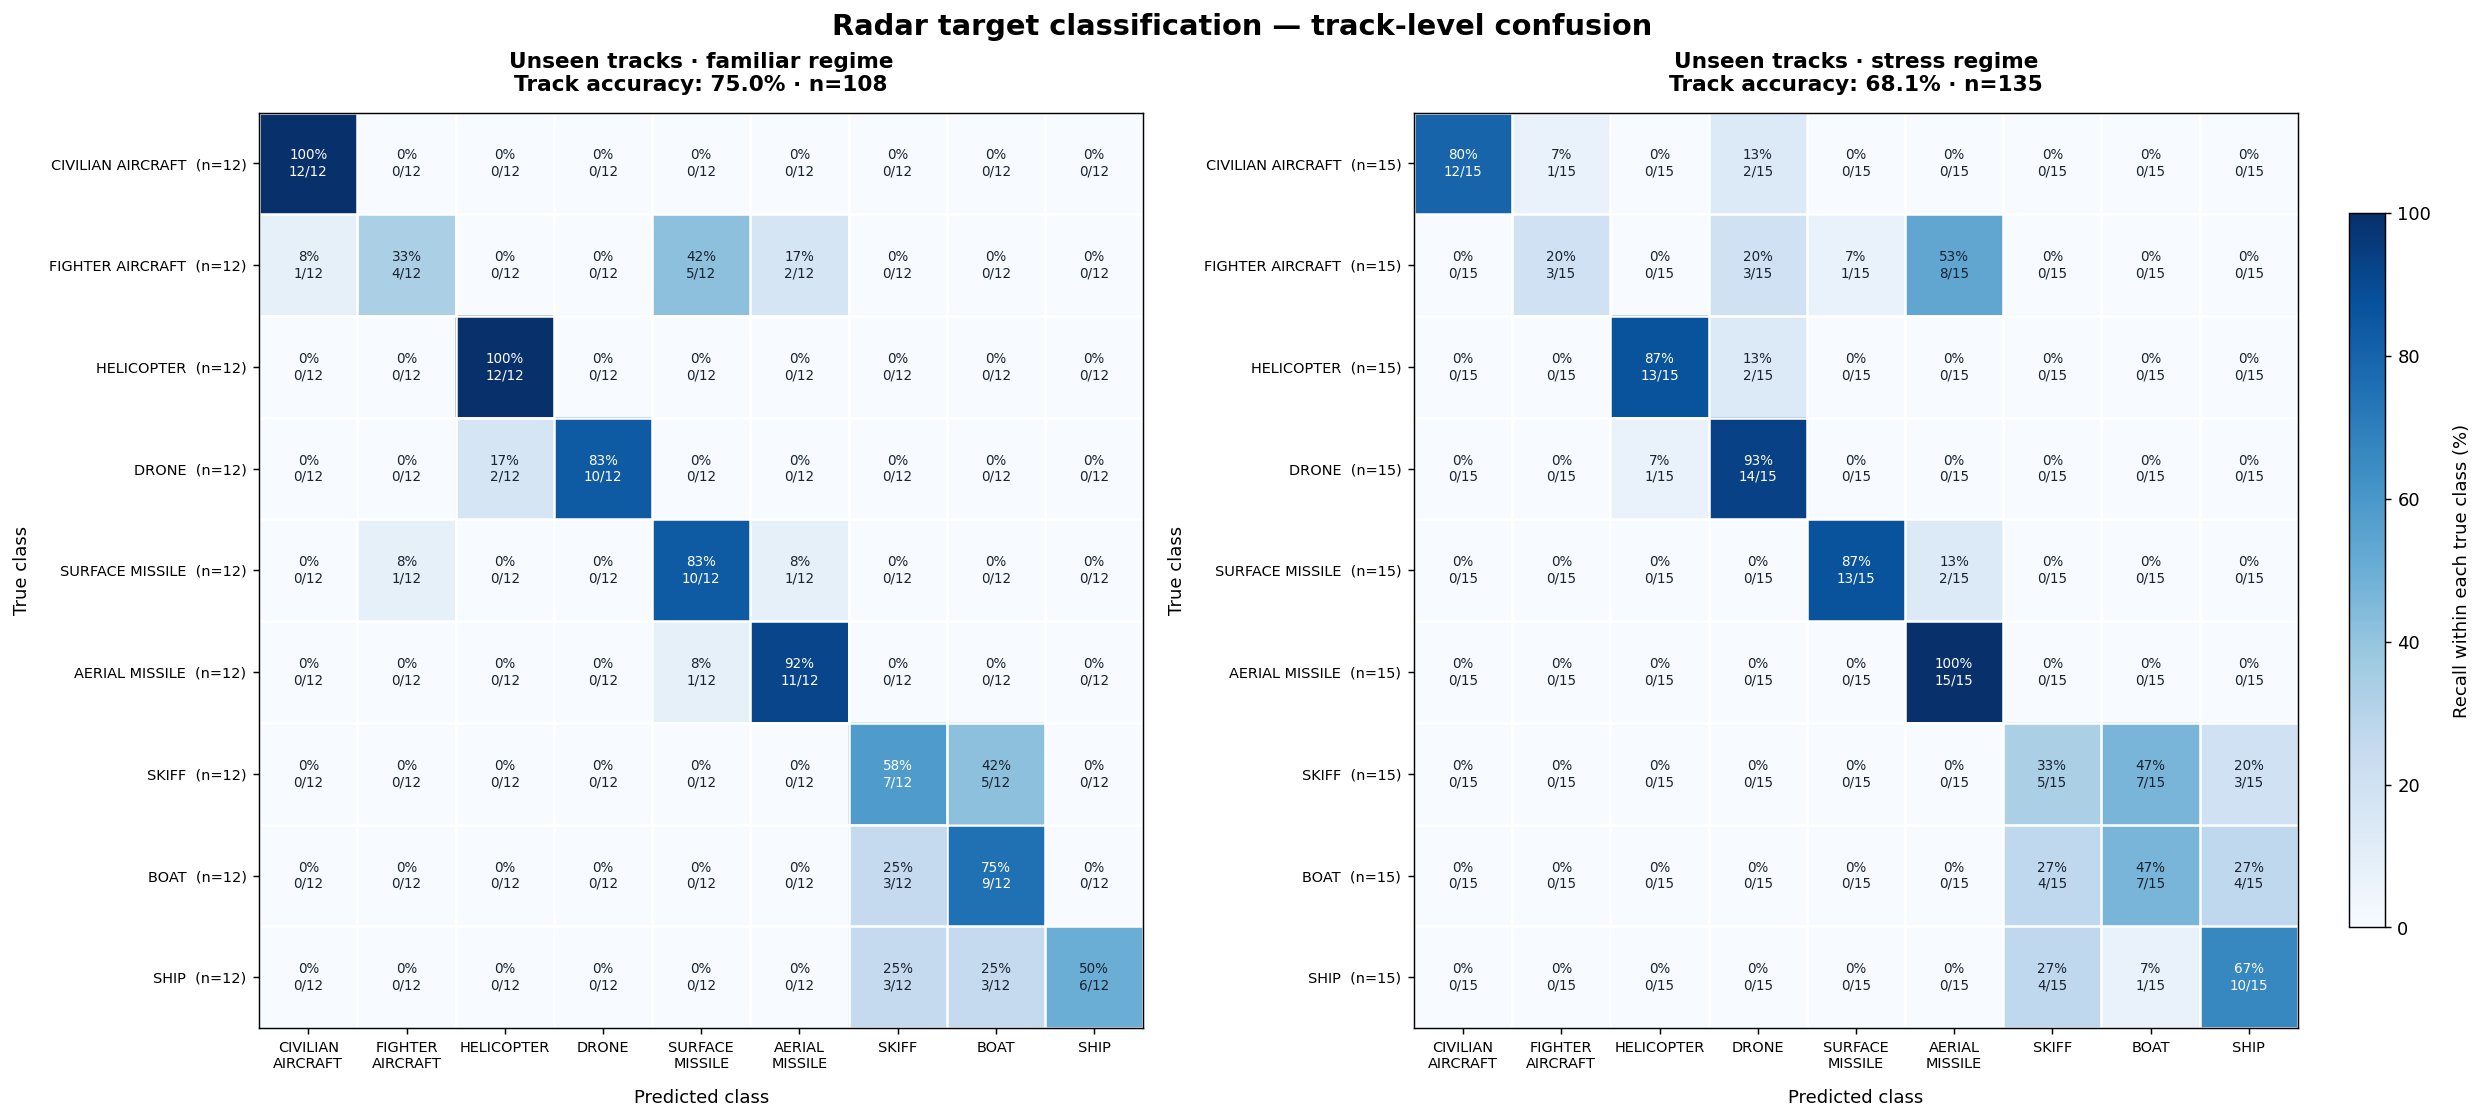

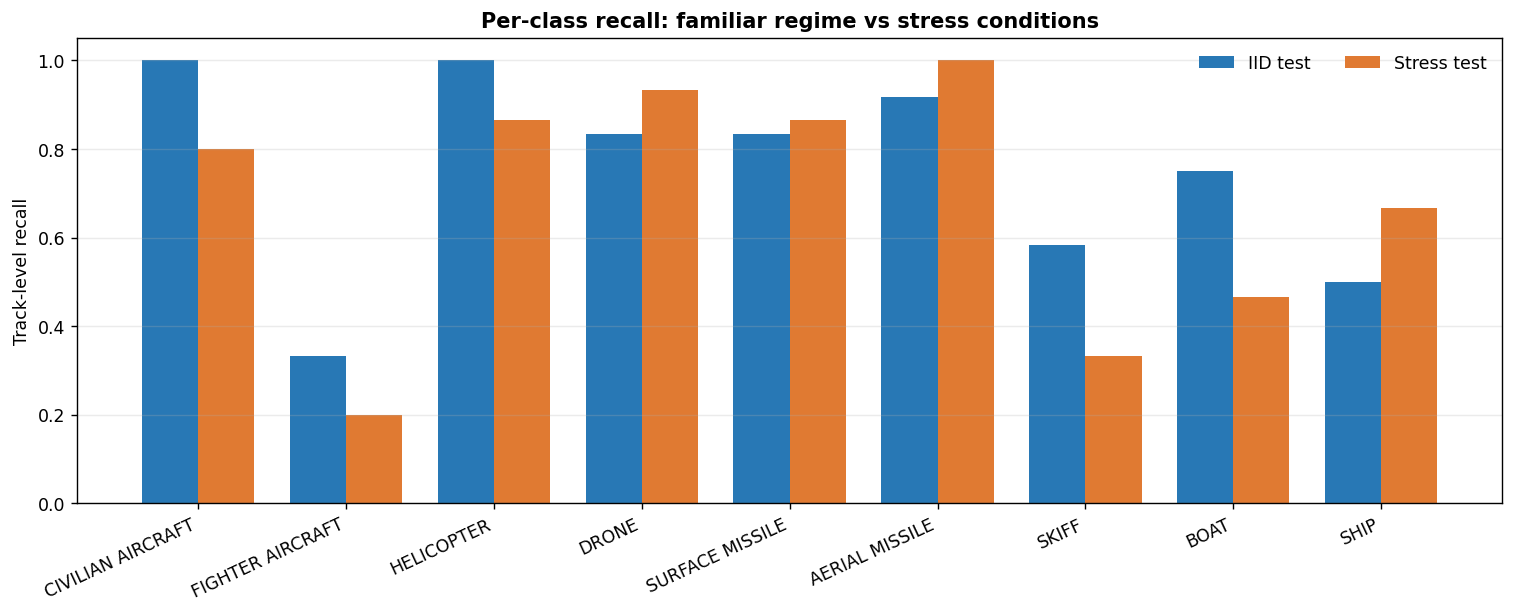

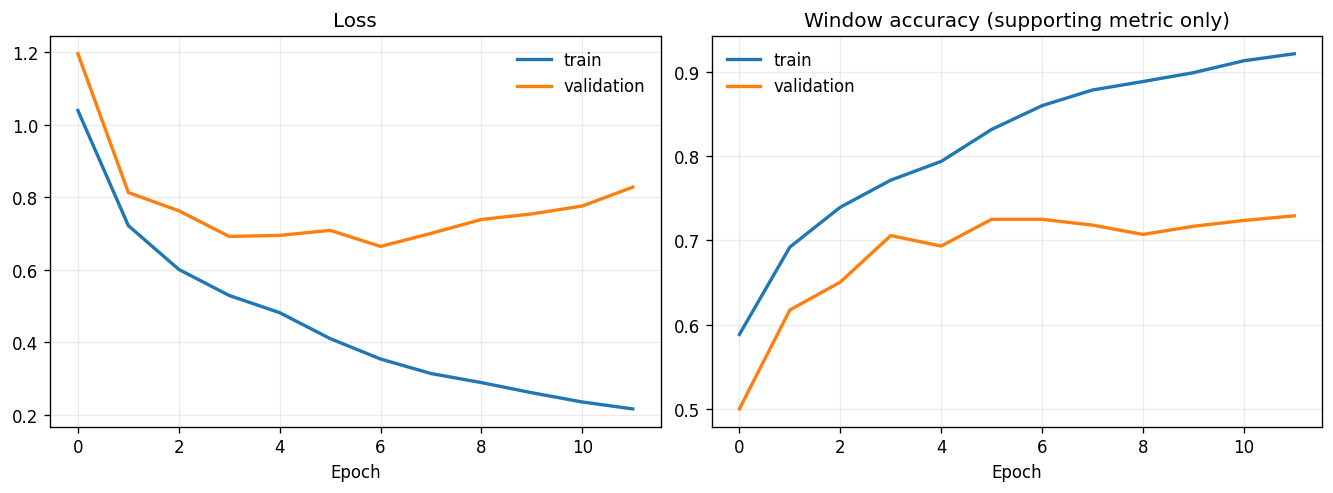

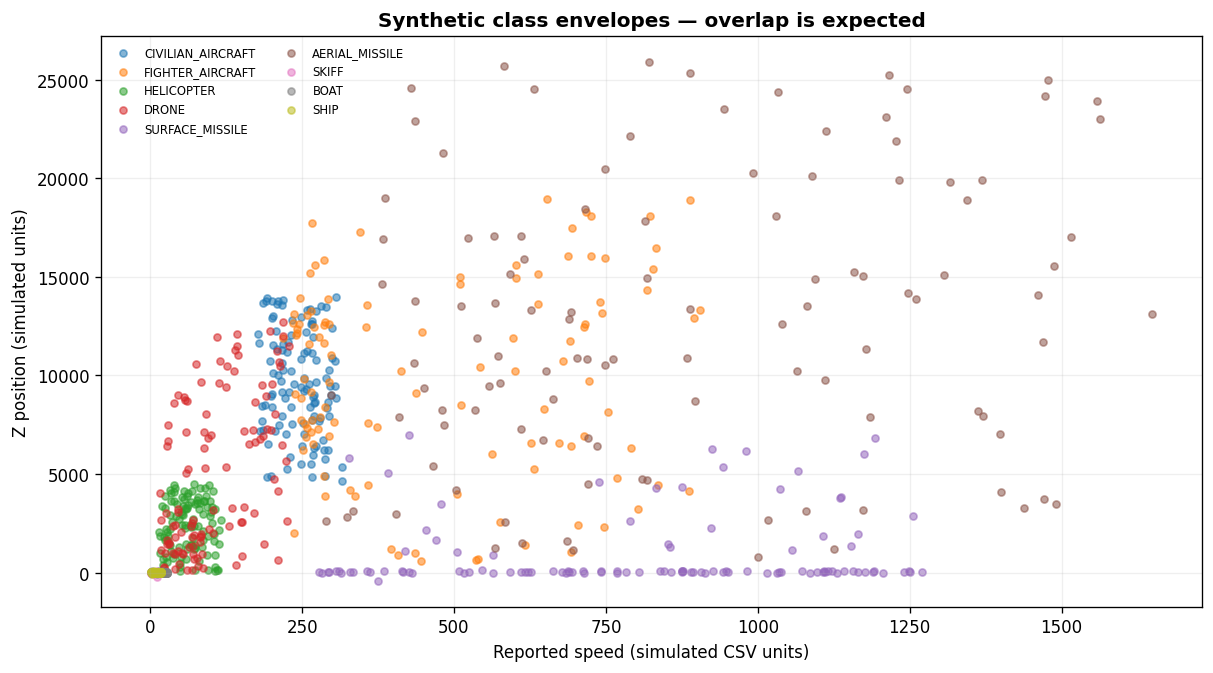

Interpretation: IID test measures unseen-track generalization within a familiar regime; stress test measures robustness under shift.
Neither score is real-radar accuracy. The real CSV is unlabelled and is used for inference only.


In [7]:
# Scores are computed for both held-out suites. Neither test suite is used to tune training.
val_probs = model.predict(X_val, batch_size=BATCH_SIZE, verbose=0)
iid_probs = model.predict(X_iid_test, batch_size=BATCH_SIZE, verbose=0)
stress_probs = model.predict(X_stress_test, batch_size=BATCH_SIZE, verbose=0)

def track_level_results(probs, meta):
    rows = []
    temp = meta.reset_index(drop=True).copy()
    for tid, idx in temp.groupby("track_no", sort=False).groups.items():
        ix = np.asarray(list(idx), dtype=int)
        p = probs[ix].mean(axis=0)
        rows.append({"track_no": tid, "true_class": temp.loc[ix[0], "true_class"],
                     "predicted_class": str(label_encoder.inverse_transform([int(np.argmax(p))])[0]),
                     "mean_model_score": float(np.max(p)), "n_windows": len(ix),
                     "is_disguised": bool(temp.loc[ix[0], "is_disguised"])})
    return pd.DataFrame(rows)

iid_track_results = track_level_results(iid_probs, meta_iid_test)
stress_track_results = track_level_results(stress_probs, meta_stress_test)

def print_track_report(title, results):
    acc = accuracy_score(results["true_class"], results["predicted_class"])
    print(f"\n{title} — TRACK-level accuracy: {acc:.3f} ({int((results.true_class == results.predicted_class).sum())}/{len(results)})")
    print(classification_report(results.true_class, results.predicted_class,
                                labels=CLASSES, target_names=CLASSES, zero_division=0, digits=2))
    return acc

iid_accuracy = print_track_report("IID unseen-track test", iid_track_results)
stress_accuracy = print_track_report("Unseen stress test", stress_track_results)

# Professional confusion matrices: row-normalized recall percentages plus raw counts/support.
# Consistent class order/scales make IID-vs-stress differences straightforward to compare.
DISPLAY_NAMES = {
    "CIVILIAN_AIRCRAFT": "CIVILIAN\nAIRCRAFT",
    "FIGHTER_AIRCRAFT": "FIGHTER\nAIRCRAFT",
    "HELICOPTER": "HELICOPTER",
    "DRONE": "DRONE",
    "SURFACE_MISSILE": "SURFACE\nMISSILE",
    "AERIAL_MISSILE": "AERIAL\nMISSILE",
    "SKIFF": "SKIFF",
    "BOAT": "BOAT",
    "SHIP": "SHIP",
}

def plot_confusion_panel(ax, results, title):
    cm = confusion_matrix(results["true_class"], results["predicted_class"], labels=CLASSES)
    support = cm.sum(axis=1)
    row_pct = np.divide(cm, support[:, None], out=np.zeros_like(cm, dtype=float), where=support[:, None] != 0) * 100.0
    im = ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(np.arange(len(CLASSES)), [DISPLAY_NAMES[c] for c in CLASSES], rotation=0, ha="center", fontsize=8)
    ax.set_yticks(np.arange(len(CLASSES)), [f"{DISPLAY_NAMES[c].replace(chr(10), ' ')}  (n={support[i]})" for i, c in enumerate(CLASSES)], fontsize=8)
    ax.set_xlabel("Predicted class", labelpad=10, fontweight="medium")
    ax.set_ylabel("True class", labelpad=10, fontweight="medium")
    acc = accuracy_score(results["true_class"], results["predicted_class"])
    ax.set_title(f"{title}\nTrack accuracy: {acc:.1%} · n={len(results)}", fontsize=12, fontweight="bold", pad=12)
    ax.set_xticks(np.arange(-.5, len(CLASSES), 1), minor=True)
    ax.set_yticks(np.arange(-.5, len(CLASSES), 1), minor=True)
    ax.grid(which="minor", color="white", linestyle="-", linewidth=1.4)
    ax.tick_params(which="minor", bottom=False, left=False)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            pct = row_pct[i, j]
            count = int(cm[i, j])
            label = f"{pct:.0f}%\n{count}/{int(support[i])}"
            ax.text(j, i, label, ha="center", va="center", fontsize=7.5,
                    color="white" if pct >= 55 else "#182230", fontweight="medium" if count else "normal")
    return im

fig, axes = plt.subplots(1, 2, figsize=(19, 8.5), dpi=130, constrained_layout=True)
im0 = plot_confusion_panel(axes[0], iid_track_results, "Unseen tracks · familiar regime")
im1 = plot_confusion_panel(axes[1], stress_track_results, "Unseen tracks · stress regime")
cbar = fig.colorbar(im1, ax=axes, shrink=0.78, pad=0.025)
cbar.set_label("Recall within each true class (%)", rotation=90, labelpad=12)
fig.suptitle("Radar target classification — track-level confusion", fontsize=16, fontweight="bold")
plt.show()

# Compact per-class comparison: helps locate which classes lose recall under stress.
def per_class_recall(results):
    cm = confusion_matrix(results["true_class"], results["predicted_class"], labels=CLASSES)
    denom = cm.sum(axis=1)
    return np.divide(np.diag(cm), denom, out=np.zeros(len(CLASSES), dtype=float), where=denom != 0)
recall_iid = per_class_recall(iid_track_results)
recall_stress = per_class_recall(stress_track_results)
x = np.arange(len(CLASSES)); width = 0.38
fig, ax = plt.subplots(figsize=(12, 4.8), dpi=125, constrained_layout=True)
ax.bar(x - width/2, recall_iid, width, label="IID test", color="#2878B5")
ax.bar(x + width/2, recall_stress, width, label="Stress test", color="#E07A32")
ax.set_xticks(x, [DISPLAY_NAMES[c].replace("\n", " ") for c in CLASSES], rotation=25, ha="right")
ax.set_ylim(0, 1.05); ax.set_ylabel("Track-level recall")
ax.set_title("Per-class recall: familiar regime vs stress conditions", fontweight="bold")
ax.grid(axis="y", alpha=0.25); ax.legend(frameon=False, ncol=2)
plt.show()

# Training diagnostics. The best validation weights are restored by EarlyStopping.
fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=120, constrained_layout=True)
axes[0].plot(history.history.get("loss", []), label="train", linewidth=2)
axes[0].plot(history.history.get("val_loss", []), label="validation", linewidth=2)
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].grid(alpha=0.25); axes[0].legend(frameon=False)
axes[1].plot(history.history.get("accuracy", []), label="train", linewidth=2)
axes[1].plot(history.history.get("val_accuracy", []), label="validation", linewidth=2)
axes[1].set_title("Window accuracy (supporting metric only)"); axes[1].set_xlabel("Epoch"); axes[1].grid(alpha=0.25); axes[1].legend(frameon=False)
plt.show()

# Visualize class envelope overlap; descriptive only, not proof of real-world separation.
first_rows = sim_features.groupby("track_no", sort=False).first().reset_index()
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=120, constrained_layout=True)
for c in CLASSES:
    d = first_rows[first_rows["_true_class"] == c]
    ax.scatter(d["vel_mag"], d["pos_z"], s=18, alpha=0.55, label=c)
ax.set_xlabel("Reported speed (simulated CSV units)"); ax.set_ylabel("Z position (simulated units)")
ax.set_title("Synthetic class envelopes — overlap is expected", fontweight="bold")
ax.grid(alpha=0.2); ax.legend(fontsize=7, ncol=2, frameon=False)
plt.show()

print("Interpretation: IID test measures unseen-track generalization within a familiar regime; stress test measures robustness under shift.")
print("Neither score is real-radar accuracy. The real CSV is unlabelled and is used for inference only.")

## 6. Load the unlabelled ICD CSV and audit its conventions

The CSV is inference-only. The classifier never uses `track_class`, `track_type`, `track_category_val`, simulator truth fields, or track metadata as labels/features. An axis audit checks whether velocity components align with position derivatives; it **does not automatically swap axes**. Only enable the optional mapping after the ICD confirms it.

In [8]:
CSV_CANDIDATES = [
    Path("radar_data(1).csv"), Path("radar_data.csv"),
    Path("/content/radar_data(1).csv"), Path("/content/radar_data.csv"),
    Path("/mnt/data/radar_data(1).csv"), Path("/mnt/data/radar_data.csv"),
]
CSV_PATH = next((p for p in CSV_CANDIDATES if p.exists()), None)
if CSV_PATH is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise RuntimeError("No CSV uploaded.")
        CSV_PATH = Path(next(iter(uploaded.keys())))
    except ImportError:
        CSV_PATH = Path(input("Enter CSV path: ").strip().strip('"'))
if not CSV_PATH.exists():
    raise FileNotFoundError(CSV_PATH)

# sep=None lets pandas infer comma-delimited CSV or tab-delimited pasted text files.
raw_csv = pd.read_csv(CSV_PATH, sep=None, engine="python")
if len(raw_csv.columns) == 1 and isinstance(raw_csv.columns[0], str) and "\t" in raw_csv.columns[0]:
    # Defensive fallback for text pasted with literal tab separators.
    raw_csv = pd.read_csv(CSV_PATH, sep="\t")
if "track_no" not in raw_csv.columns:
    raw_csv["track_no"] = 1
if "ntp_sec" not in raw_csv.columns:
    raw_csv["ntp_sec"] = np.arange(len(raw_csv), dtype=float) * SAMPLE_SECONDS
raw_csv = raw_csv.dropna(subset=["track_no", "ntp_sec"]).copy().reset_index(drop=True)
# Stable row ID lets us compute each track's causal rolling/cumulative features once,
# then replay those rows in global timestamp order without mixing track histories.
raw_csv["_packet_id"] = np.arange(len(raw_csv), dtype=np.int64)
print("CSV:", CSV_PATH, "| rows:", len(raw_csv), "| tracks:", raw_csv.track_no.nunique())
print("Target labels from CSV used: NO")
print("\nCoordinate audit before any mapping:")
coordinate_report = coordinate_frame_audit(raw_csv)
if CONFIRM_VELOCITY_ACCEL_XY_SWAP:
    # Explicitly opt in only after checking the ICD. Never infer this mapping from correlation alone.
    for a, b in [("vel_x", "vel_y"), ("accel_x", "accel_y"),
                 ("std_dev_vx", "std_dev_vy"), ("std_dev_ax", "std_dev_ay")]:
        if a in raw_csv.columns and b in raw_csv.columns:
            raw_csv[[a, b]] = raw_csv[[b, a]].to_numpy()
    print("⚠️ Applied the explicitly configured X/Y velocity/acceleration swap. Verify against ICD documentation.")
    coordinate_report = coordinate_frame_audit(raw_csv)
coordinate_mapping_suspect = False
if not coordinate_report.empty and {"reported_velocity_axis", "corr_with_dpos_x", "corr_with_dpos_y"}.issubset(coordinate_report.columns):
    rx = coordinate_report[coordinate_report["reported_velocity_axis"] == "x"]
    ry = coordinate_report[coordinate_report["reported_velocity_axis"] == "y"]
    if len(rx) and len(ry):
        rx, ry = rx.iloc[0], ry.iloc[0]
        coordinate_mapping_suspect = bool(
            (pd.notna(rx["corr_with_dpos_y"]) and (pd.isna(rx["corr_with_dpos_x"]) or rx["corr_with_dpos_y"] > rx["corr_with_dpos_x"] + 0.25))
            or (pd.notna(ry["corr_with_dpos_x"]) and (pd.isna(ry["corr_with_dpos_y"]) or ry["corr_with_dpos_x"] > ry["corr_with_dpos_y"] + 0.25))
        )
if coordinate_mapping_suspect and not CONFIRM_VELOCITY_ACCEL_XY_SWAP:
    print("⚠️ Classification status will include VERIFY ICD AXES until the coordinate convention is confirmed.")
unc_present = [c for c in UNCERTAINTY_COLS if c in raw_csv.columns]
if unc_present:
    print(f"Uncertainty/covariance columns present: {len(unc_present)}; retained for diagnostics only.")
real_features = robust_feature_extractor(raw_csv)

real_matrix = imputer.transform(real_features[FEATURE_COLS])
real_scaled_array = np.clip(scaler.transform(real_matrix), -8, 8)
shift_share = np.mean(np.abs(real_scaled_array) > 5.0, axis=0)
shift_report = pd.Series(shift_share, index=FEATURE_COLS).sort_values(ascending=False)
print("\nFeatures with >10% of rows beyond 5 robust-scaler units (diagnostic, not a verdict):")
print(shift_report[shift_report > 0.10].to_string() if (shift_report > 0.10).any() else "None detected by this simple check.")
print("⚠️ No outlier warning does NOT prove the real data matches synthetic training or that model scores are calibrated.")

Saving radar_data.csv to radar_data.csv
CSV: radar_data.csv | rows: 82 | tracks: 1
Target labels from CSV used: NO

Coordinate audit before any mapping:
Position/velocity axis audit (diagnostic only; no automatic axis swapping):


,reported_velocity_axis,corr_with_dpos_x,corr_with_dpos_y,corr_with_dpos_z
0,x,-0.024,0.998,-0.027
1,y,0.997,0.035,-0.030
2,z,0.105,0.053,0.593


⚠️ vel_x aligns more with d(pos_y) than d(pos_x). Verify the ICD axis convention before using signed axis features.
⚠️ vel_y aligns more with d(pos_x) than d(pos_y). Verify the ICD axis convention before using signed axis features.
⚠️ Classification status will include VERIFY ICD AXES until the coordinate convention is confirmed.
Uncertainty/covariance columns present: 12; retained for diagnostics only.

Features with >10% of rows beyond 5 robust-scaler units (diagnostic, not a verdict):
None detected by this simple check.
⚠️ No outlier warning does NOT prove the real data matches synthetic training or that model scores are calibrated.


## 7. Live replay — preserved from the previous version

The feed is intentionally unchanged: append-only packet-by-packet text in global timestamp order; each track retains its own sequence and score state; no `clear_output`, no plot redraws, and no blinking display. Plots render once after replay finishes.

In [9]:
# 7. LIVE FEED — append-only packet-by-packet replay (NO blinking dashboard/plots)
import time
from collections import deque

EMA_ALPHA = 0.12                  # score smoothing for display; not probability calibration
MIN_STABLE_STREAK = 3
LIVE_HISTORY_POINTS = 240
FOCUS_TRACK = None                # None = track with most packets; or specify an exact track_no

class_order = list(label_encoder.classes_)
feature_lookup = real_features.set_index("_packet_id", drop=False)
scaled_lookup = {int(pid): np.asarray(vec, dtype=np.float32)
                 for pid, vec in zip(real_features["_packet_id"].astype(int), real_scaled_array)}
ordered = raw_csv.sort_values("ntp_sec", kind="stable").reset_index(drop=True)
track_packet_counts = ordered.groupby("track_no", sort=False).size()
if FOCUS_TRACK is None:
    focus_track = track_packet_counts.idxmax()
else:
    if FOCUS_TRACK not in set(ordered["track_no"].tolist()):
        raise ValueError(f"FOCUS_TRACK={FOCUS_TRACK!r} not found in CSV track_no values")
    focus_track = FOCUS_TRACK

stream_rows = []
track_states = {}
print("📡 LIVE RADAR REPLAY — append-only feed; plots are deferred until the end", flush=True)
print(f"File: {CSV_PATH} | packets: {len(ordered)} | tracks: {ordered['track_no'].nunique()} | focus track: {focus_track}", flush=True)
print("Scores are uncalibrated synthetic-model scores; input CSV labels are never used.\n", flush=True)

for packet_idx, packet in ordered.iterrows():
    tid = packet["track_no"]
    packet_id = int(packet["_packet_id"])
    scaled_row = scaled_lookup[packet_id]
    feat_row = feature_lookup.loc[packet_id]

    state = track_states.get(tid)
    if state is None:
        state = {
            "scaled_window": deque(maxlen=SEQUENCE_LENGTH),
            "history": deque(maxlen=LIVE_HISTORY_POINTS),
            "ema": None, "count": 0, "candidate": None, "candidate_streak": 0,
            "stable": "WARMING_UP", "last_seen": float(packet["ntp_sec"]),
            "last_window_candidate": "WARMING_UP", "last_window_score": np.nan,
            "last_track_candidate": "WARMING_UP", "last_track_score": np.nan,
            "last_margin": np.nan, "last_status": "PROVISIONAL — SHORT HISTORY",
            "last_speed": np.nan, "last_altitude": np.nan, "last_accel": np.nan,
        }

    # Each track has its own sequence buffer. Interleaved tracks never share packets.
    state["scaled_window"].append(scaled_row)
    available = np.asarray(state["scaled_window"], dtype=np.float32)
    warmup = state["count"] + 1 < SEQUENCE_LENGTH
    if len(available) < SEQUENCE_LENGTH:
        sequence = np.concatenate([np.repeat(available[:1], SEQUENCE_LENGTH-len(available), axis=0), available], axis=0)
    else:
        sequence = available[-SEQUENCE_LENGTH:]

    p = np.asarray(model.predict(sequence[None, ...], verbose=0)[0], dtype=float)
    p = np.clip(p, 1e-8, 1.0); p /= p.sum()
    window_idx = int(np.argmax(p))
    window_candidate = class_order[window_idx]
    window_score = float(p[window_idx])
    if state["ema"] is None:
        state["ema"] = p.copy()
    else:
        state["ema"] = (1.0-EMA_ALPHA)*state["ema"] + EMA_ALPHA*p
        state["ema"] /= state["ema"].sum()
    track_p = state["ema"].copy()
    rank = np.argsort(track_p)[::-1]
    track_idx = int(rank[0]); track_candidate = class_order[track_idx]
    track_score = float(track_p[track_idx])
    margin = float(track_p[rank[0]] - track_p[rank[1]])

    if track_candidate == state["candidate"]:
        state["candidate_streak"] += 1
    else:
        state["candidate"] = track_candidate
        state["candidate_streak"] = 1
    if not warmup and state["candidate_streak"] >= MIN_STABLE_STREAK and track_score >= 0.40 and margin >= 0.08:
        state["stable"] = track_candidate

    if warmup:
        status = "PROVISIONAL — SHORT HISTORY"
    elif track_score < 0.40 or margin < 0.08:
        status = "LOW / AMBIGUOUS MODEL EVIDENCE"
    elif coordinate_mapping_suspect and not CONFIRM_VELOCITY_ACCEL_XY_SWAP:
        status = "CANDIDATE — VERIFY ICD AXES"
    else:
        status = "SYNTHETIC-MODEL CANDIDATE — UNVERIFIED"

    getnum = lambda col: float(feat_row[col]) if col in feat_row.index and pd.notna(feat_row[col]) else np.nan
    speed, altitude, acceleration = getnum("vel_mag"), getnum("pos_z"), getnum("accel_mag")
    state["count"] += 1
    state["last_seen"] = float(packet["ntp_sec"])
    state["last_window_candidate"] = window_candidate
    state["last_window_score"] = window_score
    state["last_track_candidate"] = track_candidate
    state["last_track_score"] = track_score
    state["last_margin"] = margin
    state["last_status"] = status
    state["last_speed"] = speed; state["last_altitude"] = altitude; state["last_accel"] = acceleration
    hist_row = {
        "ntp_sec": float(packet["ntp_sec"]), "window_candidate": window_candidate,
        "window_score": window_score, "track_candidate": track_candidate,
        "track_score": track_score, "stable_hypothesis": state["stable"],
        "speed": speed, "altitude": altitude, "acceleration": acceleration,
    }
    hist_row.update({f"track_score_{c}": float(track_p[j]) for j, c in enumerate(class_order)})
    state["history"].append(hist_row)
    track_states[tid] = state

    row = {
        "track_no": tid, "ntp_sec": float(packet["ntp_sec"]),
        "packet_index_global": packet_idx+1, "packet_index_for_track": state["count"],
        "window_candidate": window_candidate, "window_score_not_calibrated": window_score,
        "track_candidate": track_candidate, "track_score_not_calibrated": track_score,
        "top2_margin_not_calibrated": margin, "stable_hypothesis": state["stable"],
        "status": status, "warmup": warmup, "speed": speed, "altitude": altitude,
        "acceleration": acceleration, "coordinate_mapping_suspect": coordinate_mapping_suspect,
        "ground_truth": "UNLABELLED — not available",
    }
    for j, c in enumerate(class_order):
        row[f"window_score_{c}"] = float(p[j])
        row[f"track_score_{c}"] = float(track_p[j])
    stream_rows.append(row)

    # Crucially: plain print only. No clear_output, dashboard redraw, display(), or plotting here.
    if PRINT_EVERY_N_PACKETS > 0 and ((packet_idx+1) % PRINT_EVERY_N_PACKETS == 0):
        print(f"📡 packet {packet_idx+1:>5}/{len(ordered)} | t={packet['ntp_sec']} | track={tid} | "
              f"window={window_candidate} ({window_score:.1%}) | track={track_candidate} ({track_score:.1%}) | "
              f"stable={state['stable']} | {status}", flush=True)
        if PLAYBACK_DELAY > 0:
            time.sleep(PLAYBACK_DELAY)

stream = pd.DataFrame(stream_rows).sort_values("ntp_sec", kind="stable").reset_index(drop=True)
stream.to_csv("radar_packet_predictions_v19.csv", index=False)

# Integrity checks: every input packet appears exactly once, and per-track counts are unchanged.
assert len(stream) == len(raw_csv), f"Output rows ({len(stream)}) != input packets ({len(raw_csv)})"
input_counts = raw_csv.groupby("track_no", sort=False).size().to_dict()
output_counts = stream.groupby("track_no", sort=False).size().to_dict()
assert input_counts == output_counts, "Per-track packet counts changed during replay"
assert stream.groupby("track_no")["packet_index_for_track"].max().to_dict() == input_counts
print("\n✅ Multi-track integrity checks passed.", flush=True)
print(f"✅ Saved packet-level predictions: radar_packet_predictions_v19.csv ({len(stream)} rows)", flush=True)

📡 LIVE RADAR REPLAY — append-only feed; plots are deferred until the end
File: radar_data.csv | packets: 82 | tracks: 1 | focus track: 1
Scores are uncalibrated synthetic-model scores; input CSV labels are never used.

📡 packet     1/82 | t=3991182426.0 | track=1.0 | window=SURFACE_MISSILE (38.7%) | track=SURFACE_MISSILE (38.7%) | stable=WARMING_UP | PROVISIONAL — SHORT HISTORY
📡 packet     2/82 | t=3991182434.0 | track=1.0 | window=SURFACE_MISSILE (35.6%) | track=SURFACE_MISSILE (38.3%) | stable=WARMING_UP | PROVISIONAL — SHORT HISTORY
📡 packet     3/82 | t=3991182444.0 | track=1.0 | window=CIVILIAN_AIRCRAFT (37.0%) | track=SURFACE_MISSILE (37.1%) | stable=WARMING_UP | PROVISIONAL — SHORT HISTORY
📡 packet     4/82 | t=3991182454.0 | track=1.0 | window=CIVILIAN_AIRCRAFT (42.4%) | track=SURFACE_MISSILE (35.3%) | stable=WARMING_UP | PROVISIONAL — SHORT HISTORY
📡 packet     5/82 | t=3991182464.0 | track=1.0 | window=CIVILIAN_AIRCRAFT (49.7%) | track=SURFACE_MISSILE (33.3%) | stable=WARMIN

## 8. Final summaries and static plots

After the live feed finishes, save one packet-level result per input packet and one final summary per track. The focus-track timeline and all-track candidate count are drawn once at the end. The feed itself stays as you requested.

✅ Saved radar_track_summary_v19.csv — 1 tracks
Track status board:


,track_no,packets_processed,first_timestamp,last_timestamp,latest_window_candidate,final_track_candidate,final_stable_hypothesis,top_model_score_not_calibrated,runner_up_class,runner_up_score_not_calibrated,window_candidate_changes,status,ground_truth
0,1.0,82,3.991182e+09,3.991183e+09,FIGHTER_AIRCRAFT,FIGHTER_AIRCRAFT,FIGHTER_AIRCRAFT,0.582058,SURFACE_MISSILE,0.315749,1,CANDIDATE — VERIFY ICD AXES,UNLABELLED — not available


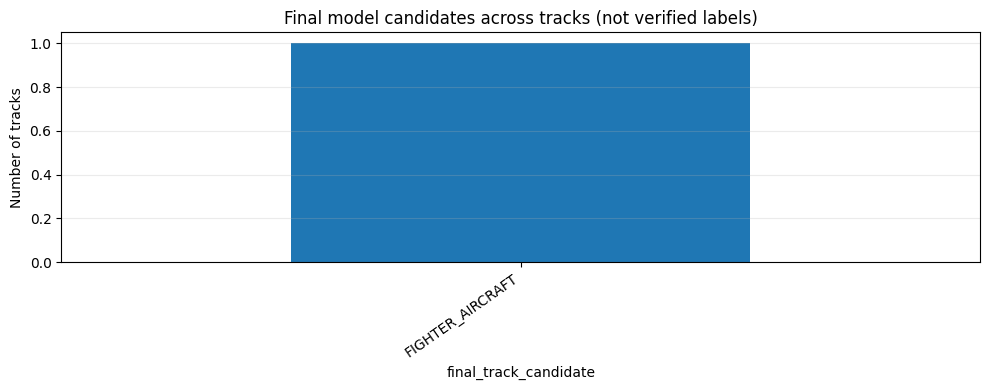

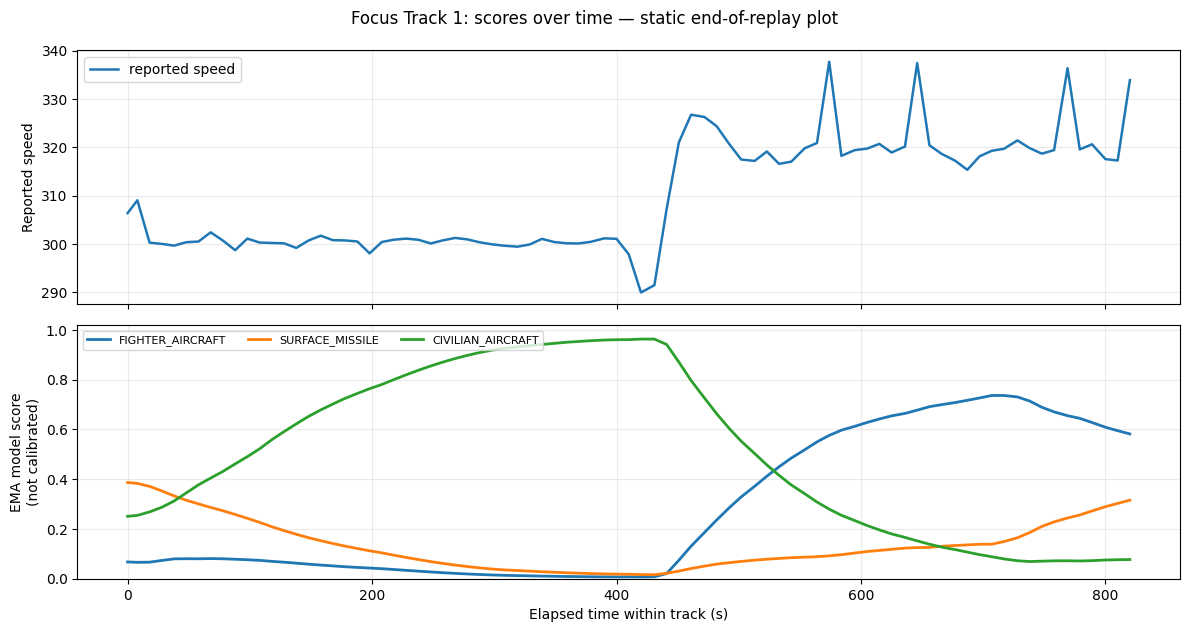

Reminder: candidates are unverified; the CSV is unlabelled and real-world accuracy cannot be calculated.


In [10]:
# 8. Final summaries and STATIC plots — rendered once, after the packet loop
summary_rows = []
for tid, g in stream.groupby("track_no", sort=False):
    g = g.sort_values("ntp_sec", kind="stable")
    last = g.iloc[-1]
    valid = g[~g["warmup"]]
    changes = int((valid["window_candidate"] != valid["window_candidate"].shift()).sum()-1) if len(valid) else 0
    score_cols = [f"track_score_{c}" for c in class_order]
    top = last[score_cols].astype(float).sort_values(ascending=False)
    summary_rows.append({
        "track_no": tid, "packets_processed": len(g),
        "first_timestamp": g["ntp_sec"].iloc[0], "last_timestamp": last["ntp_sec"],
        "latest_window_candidate": last["window_candidate"],
        "final_track_candidate": last["track_candidate"],
        "final_stable_hypothesis": last["stable_hypothesis"],
        "top_model_score_not_calibrated": float(top.iloc[0]),
        "runner_up_class": str(top.index[1].replace("track_score_", "")),
        "runner_up_score_not_calibrated": float(top.iloc[1]),
        "window_candidate_changes": max(0, changes), "status": last["status"],
        "ground_truth": "UNLABELLED — not available",
    })
track_summary = pd.DataFrame(summary_rows).sort_values("track_no", key=lambda s: s.astype(str), kind="stable")
track_summary.to_csv("radar_track_summary_v19.csv", index=False)
print(f"✅ Saved radar_track_summary_v19.csv — {len(track_summary)} tracks")
print("Track status board:")
display(track_summary.reset_index(drop=True))

# A single all-track candidate count chart.
count_data = track_summary["final_track_candidate"].value_counts().reindex(class_order, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4))
count_data[count_data > 0].sort_values(ascending=False).plot(kind="bar", ax=ax)
ax.set_ylabel("Number of tracks")
ax.set_title("Final model candidates across tracks (not verified labels)")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

# One focus-track score timeline, rendered only after the entire replay.
if focus_track in set(stream["track_no"].tolist()):
    gf = stream[stream["track_no"] == focus_track].sort_values("ntp_sec", kind="stable").copy()
    gf["elapsed_seconds"] = gf["ntp_sec"] - gf["ntp_sec"].iloc[0]
    score_cols = [f"track_score_{c}" for c in class_order]
    final_scores = gf.iloc[-1][score_cols].astype(float)
    focus_top = [c.replace("track_score_", "") for c in final_scores.sort_values(ascending=False).index[:3]]
    fig, axes = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True)
    axes[0].plot(gf["elapsed_seconds"], gf["speed"], linewidth=1.8, label="reported speed")
    axes[0].set_ylabel("Reported speed"); axes[0].grid(True, alpha=0.25); axes[0].legend(loc="upper left")
    for c in focus_top:
        axes[1].plot(gf["elapsed_seconds"], gf[f"track_score_{c}"], label=c, linewidth=2)
    axes[1].set_ylim(0, 1.02); axes[1].set_xlabel("Elapsed time within track (s)")
    axes[1].set_ylabel("EMA model score\n(not calibrated)"); axes[1].grid(True, alpha=0.25)
    axes[1].legend(loc="upper left", ncol=3, fontsize=8)
    fig.suptitle(f"Focus Track {focus_track}: scores over time — static end-of-replay plot")
    plt.tight_layout(); plt.show()

print("Reminder: candidates are unverified; the CSV is unlabelled and real-world accuracy cannot be calculated.")

## How to interpret Model 19

- More independent tracks are added to training; the maximum epoch count is larger only as a ceiling. Early stopping restores the best validation weights, so do not force training to finish every epoch.
- **IID test accuracy** and **stress-test accuracy** answer different questions. The former assesses unseen tracks in a familiar regime; the latter assesses robustness to stronger noise/dropout and rougher sea conditions.
- The confusion matrix shows row-normalized recall and raw `correct / support` counts. Read the stress matrix separately; its lower score is not directly comparable with earlier easier tests.
- The real CSV stays unlabelled. Its model output is a synthetic-trained candidate, not verified ground truth.
- The live feed format is preserved. Set `PLAYBACK_DELAY = 0.0` to replay quickly.

## 9. Check the vessel wave model visually

This diagnostic plots one simulated vessel track from the rough-sea stress-test family. The physical reference height includes low-frequency heave; the reported `pos_z` adds sensor measurement noise. It is a filtered track-level wave response, not a high-rate ocean-wave simulation.

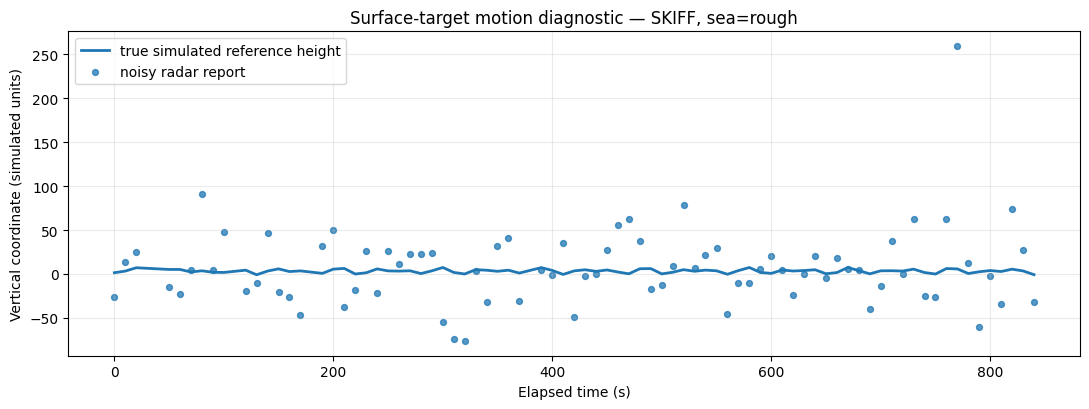

Synthetic wave plot is a simulator diagnostic, not evidence about the unlabelled real track.


In [11]:
# Static diagnostic: true vessel reference-height motion vs noisy reported measurement.
sea_candidates = synthetic_raw[
    synthetic_raw["_true_class"].isin(["SKIFF", "BOAT", "SHIP"])
    & (synthetic_raw["_scenario_family"] == TEST_FAMILY)
]
if not sea_candidates.empty:
    vessel_id = sea_candidates["track_no"].iloc[0]
    vg = sea_candidates[sea_candidates["track_no"] == vessel_id].sort_values("ntp_sec", kind="stable").copy()
    vg["elapsed_seconds"] = vg["ntp_sec"] - vg["ntp_sec"].iloc[0]
    fig, ax = plt.subplots(figsize=(11, 4.2))
    ax.plot(vg["elapsed_seconds"], vg["_true_pos_z"], linewidth=2, label="true simulated reference height")
    ax.scatter(vg["elapsed_seconds"], vg["pos_z"], s=18, alpha=0.75, label="noisy radar report")
    ax.set_xlabel("Elapsed time (s)"); ax.set_ylabel("Vertical coordinate (simulated units)")
    ax.set_title(f"Surface-target motion diagnostic — {vg['_true_class'].iloc[0]}, sea={vg['_sea_state'].iloc[0]}")
    ax.grid(True, alpha=0.25); ax.legend(); plt.tight_layout(); plt.show()
else:
    print("No surface-vessel records found in the held-out test family; check simulator settings.")
print("Synthetic wave plot is a simulator diagnostic, not evidence about the unlabelled real track.")

## What counts as progress?

1. First compare the new **IID held-out track** result with the separate **stress-test** result. A large gap means robustness to distribution shift is the dominant issue.
2. Use per-class recall and the confusion matrix to target improvements, especially the airborne missile/fighter confusions and skiff/boat/ship confusions.
3. More tracks help only when they add independent trajectory, manoeuvre, sea-state and sensor-error variation. More epochs alone do not fix a simulator/model mismatch.
4. Preserve the Model-11-style packet replay. Do not tune thresholds to force a desired target label.
5. Verify the real ICD coordinate conventions before relying on signed axis features. This CSV is unlabelled, so it cannot provide real-world accuracy.
6. The simulator is a research approximation. Validate against independently labelled real tracks when available before making operational performance claims.